In [53]:
import numpy as np
import pandas as pd 

In [54]:
Dataframe = pd.read_csv("sales_data_sample.csv" , encoding="latin1")

In [55]:
df = Dataframe
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [56]:
print("Information about Dataset : \n")
df.info()

Information about Dataset : 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2

In [57]:
print("Statical Data :")
df.describe()

Statical Data :


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.00000,2823.000000
mean,10258.725115,35.092809,83.658544,6.466171,3553.889072,2.717676,7.092455,2003.81509,100.715551
std,92.085478,9.741443,20.174277,4.225841,1841.865106,1.203878,3.656633,0.69967,40.187912
min,10100.000000,6.000000,26.880000,1.000000,482.130000,1.000000,1.000000,2003.00000,33.000000
25%,10180.000000,27.000000,68.860000,3.000000,2203.430000,2.000000,4.000000,2003.00000,68.000000
50%,10262.000000,35.000000,95.700000,6.000000,3184.800000,3.000000,8.000000,2004.00000,99.000000
75%,10333.500000,43.000000,100.000000,9.000000,4508.000000,4.000000,11.000000,2004.00000,124.000000
max,10425.000000,97.000000,100.000000,18.000000,14082.800000,4.000000,12.000000,2005.00000,214.000000


In [58]:
print("Shape of Dataset : ",df.shape)

Shape of Dataset :  (2823, 25)


In [59]:
df.columns

Index(['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER',
       'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID',
       'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE',
       'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE',
       'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME',
       'DEALSIZE'],
      dtype='object')

In [60]:
# Drop unnecessay Columns
df = df[['ORDERLINENUMBER','SALES']]

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ORDERLINENUMBER  2823 non-null   int64  
 1   SALES            2823 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 44.2 KB


In [62]:
df.isnull().sum()

ORDERLINENUMBER    0
SALES              0
dtype: int64

In [63]:
# Standard PreProcessing 

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_values = scaler.fit_transform(df.values)

# This tries to make the Mean 0 and the Standard Deviation as 1


In [64]:
# import KMeanClustering

from sklearn.cluster import KMeans

#Finding k with elbow method 
#Within CLuster Sum of Squares Of Distances

wcss=[]

for i in range(1,11):
    model = KMeans(n_clusters=i)
    model.fit_predict(scaled_values)
    wcss.append(model.inertia_)

# The inertia is computed as the sum of squared distances from each data point to the center of its assigned cluster 



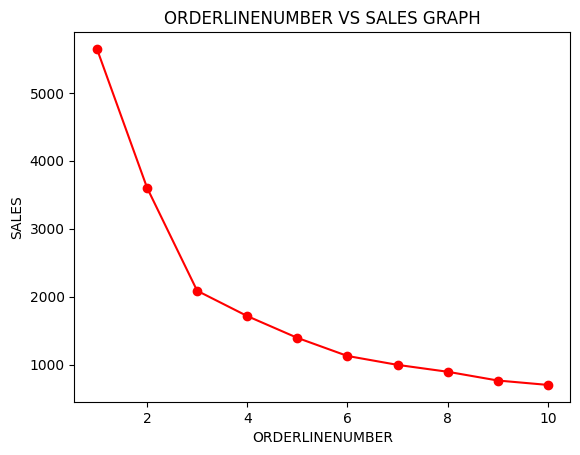

In [65]:
#Plot the elbow Graph

import matplotlib.pyplot as plt

plt.plot(range(1,11),wcss,'ro-')
plt.xlabel("ORDERLINENUMBER")
plt.ylabel("SALES")
plt.title("ORDERLINENUMBER VS SALES GRAPH")
plt.show()


In [66]:
# K-7 seems to be a better choice for  k

kmeans_model = KMeans(n_clusters=7)
cluster = kmeans_model.fit_predict(scaled_values)

In [67]:
import warnings
warnings.filterwarnings('ignore')
df['Cluster'] = cluster

In [68]:
df

,ORDERLINENUMBER,SALES,Cluster
0,2,2871.00,6
1,5,2765.90,4
2,2,3884.34,0
3,6,3746.70,0
4,14,5205.27,2
...,...,...,...
2818,15,2244.40,1
2819,1,3978.51,0
2820,4,5417.57,0
2821,1,2116.16,6


Text(0.5, 1.0, 'ORDERLINENUMBER VS SALES GRAPH')

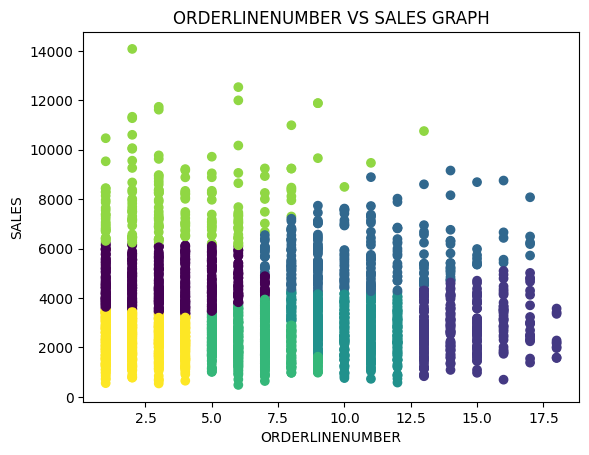

In [69]:
plt.scatter(df['ORDERLINENUMBER'], df['SALES'],c=df['Cluster'])
plt.xlabel("ORDERLINENUMBER")
plt.ylabel("SALES")
plt.title("ORDERLINENUMBER VS SALES GRAPH")